In [ ]:
# ==========================================
# 1. INSTALACIÓN Y CARGA
# ==========================================
!pip install -q opencv-python-headless
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Sube tus 5 imágenes (referencia.jpg, oscura.jpg, desenfocada.jpg, fondo_complejo.jpg, angulo.jpg):")
cargados = files.upload()


Sube tus 5 imágenes (referencia.jpg, oscura.jpg, desenfocada.jpg, fondo_complejo.jpg, angulo.jpg):


Saving angulo.jpg to angulo (1).jpg
Saving desenfocada.jpg to desenfocada (1).jpg
Saving fondo_complejo.jpg to fondo_complejo (1).jpg
Saving oscura.jpg to oscura (1).jpg
Saving referencia.jpg to referencia (1).jpg


In [ ]:
# ==========================================
# 2. FUNCIÓN PARA CALCULAR MÉTRICAS
# ==========================================
def analizar_imagen(ruta):
    img = cv2.imread(ruta)
    if img is None:
        return None

    # Datos básicos
    alto, ancho, canales = img.shape

    # Brillo y Contraste (en escala de grises)
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    brillo = gris.mean()
    contraste = gris.std()

    # Nitidez (Varianza del Laplaciano)
    nitidez = cv2.Laplacian(gris, cv2.CV_64F).var()

    return img, gris, {
        'Resolución': f"{ancho}x{alto}",
        'Canales': canales,
        'Brillo': round(brillo, 2),
        'Contraste': round(contraste, 2),
        'Nitidez': round(nitidez, 2)
    }

In [ ]:
# ==========================================
# 3. DIAGNÓSTICO DE LAS 5 IMÁGENES
# ==========================================
imagenes = ['referencia.jpg', 'oscura.jpg', 'desenfocada.jpg', 'fondo_complejo.jpg', 'angulo.jpg']
resultados = {}

for nombre in imagenes:
    if nombre in cargados:
        img, gris, metricas = analizar_imagen(nombre)
        resultados[nombre] = metricas
        print(f"--- {nombre} ---")
        for k, v in metricas.items():
            print(f"{k}: {v}")
        print("\n")

In [ ]:
# ==========================================
# 4. TRATAMIENTO DE LA IMAGEN PROBLEMÁTICA
# ==========================================
# Tomamos la imagen 'oscura.jpg' como la problemática
ruta_problematica = 'oscura.jpg'
img_orig, gris_orig, metricas_orig = analizar_imagen(ruta_problematica)

# Tratamiento: Conversión a espacio HSV y Ecualización del canal V (Valor/Brillo)
# Esto mejora el contraste y brillo sin alterar los colores (tono y saturación)
hsv = cv2.cvtColor(img_orig, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)
v_eq = cv2.equalizeHist(v)
hsv_eq = cv2.merge((h, s, v_eq))
img_mejorada = cv2.cvtColor(hsv_eq, cv2.COLOR_HSV2BGR)

gris_mejorada = cv2.cvtColor(img_mejorada, cv2.COLOR_BGR2GRAY)

metricas_mejoradas = {
    'Resolución': f"{img_mejorada.shape[1]}x{img_mejorada.shape[0]}",
    'Canales': img_mejorada.shape[2],
    'Brillo': round(gris_mejorada.mean(), 2),
    'Contraste': round(gris_mejorada.std(), 2),
    'Nitidez': round(cv2.Laplacian(gris_mejorada, cv2.CV_64F).var(), 2)
}

print("--- Métricas Original (Oscura) ---")
for k, v in metricas_orig.items():
    print(f"{k}: {v}")

print("\n--- Métricas Mejorada (Ecualizada) ---")
for k, v in metricas_mejoradas.items():
    print(f"{k}: {v}")

--- Métricas Original (Oscura) ---
Resolución: 3000x4000
Canales: 3
Brillo: 75.63
Contraste: 20.74
Nitidez: 134.34

--- Métricas Mejorada (Ecualizada) ---
Resolución: 3000x4000
Canales: 3
Brillo: 123.79
Contraste: 72.06
Nitidez: 2125.17


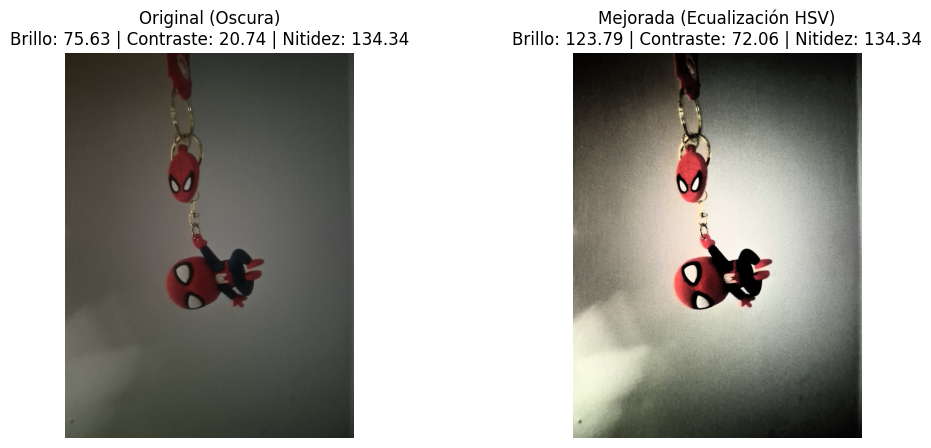

In [ ]:
# ==========================================
# 5. VISUALIZACIÓN ANTES Y DESPUÉS
# ==========================================
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB))
plt.title(f"Original (Oscura)\nBrillo: {metricas_orig['Brillo']} | Contraste: {metricas_orig['Contraste']} | Nitidez: {metricas_orig['Nitidez']}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_mejorada, cv2.COLOR_BGR2RGB))
plt.title(f"Mejorada (Ecualización HSV)\nBrillo: {metricas_mejoradas['Brillo']} | Contraste: {metricas_mejoradas['Contraste']} | Nitidez: {metricas_orig['Nitidez']}")
plt.axis('off')
plt.show()

In [ ]:
import os

# Tomamos la imagen de referencia para la prueba de formatos
img_ref = cv2.imread('referencia.jpg')

# Guardar en JPG con calidad 90 (0 a 100)
cv2.imwrite('comparacion.jpg', img_ref, [cv2.IMWRITE_JPEG_QUALITY, 90])

# Guardar en PNG (por defecto usa compresión sin pérdida)
cv2.imwrite('comparacion.png', img_ref)

# Obtener los tamaños de los archivos en Kilobytes (KB)
tam_jpg = os.path.getsize('comparacion.jpg') / 1024
tam_png = os.path.getsize('comparacion.png') / 1024

print(f"Tamaño del archivo JPG: {tam_jpg:.2f} KB")
print(f"Tamaño del archivo PNG: {tam_png:.2f} KB")

# Calcular la diferencia de peso
if tam_png > tam_jpg:
    print(f"El PNG pesa {tam_png - tam_jpg:.2f} KB más que el JPG.")
else:
    print(f"El JPG pesa {tam_jpg - tam_png:.2f} KB más que el PNG.")

Tamaño del archivo JPG: 1938.61 KB
Tamaño del archivo PNG: 14502.73 KB
El PNG pesa 12564.12 KB más que el JPG.
